# ⚙️ Setup

In [1]:
import os
import random
import time
import numpy as np
import torch
import torch.nn as nn
import seaborn as sns
import matplotlib.pyplot as plt
import torch.nn.functional as F
from matplotlib.ticker import MaxNLocator
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support, confusion_matrix 

SEED = 42

def seed_everything(seed=42):
  """Locks all random number generators across Python, NumPy, and PyTorch."""
  os.environ["PYTHONHASHSEED"] = str(seed)
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)  # For multi-GPU setups (e.g., Kaggle T4 x2)
  torch.backends.cudnn.deterministic = True
  torch.backends.cudnn.benchmark = False

seed_everything(SEED)

# ==============================================================================
# HYPERPARAMETERS & CONFIGURATION
# ==============================================================================
batch_size = 64
num_classes = 10
num_channels = 3
img_size = 64
patch_size = 4
num_patches = (img_size // patch_size) ** 2
attention_heads = 4
embedding_dim = 192
transformer_blocks = 6
mlp_nodes = embedding_dim * 4
learning_rate = 0.001
num_epochs = 50

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Seed locked to {SEED} | Device: {device}")

Seed locked to 42 | Device: cuda


# 🗂️ Dataset Setup

In [3]:
# Standard per channel mean & std for EuroSAT RGB satellite imagery
EUROSAT_MEAN = [0.3444, 0.3809, 0.4082]
EUROSAT_STD  = [0.1809, 0.1331, 0.1137]

train_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomChoice([
        transforms.RandomRotation((0, 0)),
        transforms.RandomRotation((90, 90)),
        transforms.RandomRotation((180, 180)),
        transforms.RandomRotation((270, 270)),
    ]),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15), # Randomly scales brightness, contrast, and saturation by $\pm 15\%$ ([0.85, 1.15]) so the ViT learns geometric land patterns rather than memorizing raw colors.
    transforms.ToTensor(), # convert into [0,1]
    transforms.Normalize(mean=EUROSAT_MEAN, std=EUROSAT_STD) # standard scaling
])

# Validation & Test get ONLY deterministic resizing + normalization (no random flips/rotations)
eval_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=EUROSAT_MEAN, std=EUROSAT_STD)
])


class SubsetWithTransform(Dataset):
  """
  Wraps a specific list of indices from an ImageFolder dataset and applies a
  dedicated transform pipeline on the fly whenever a sample is requested.
  """
  def __init__(self, base_dataset, indices, transform):
    self.base_dataset = base_dataset
    self.indices = indices
    self.transform = transform

  def __len__(self):
    return len(self.indices)

  def __getitem__(self, idx):
    image, label = self.base_dataset[self.indices[idx]]
    if self.transform:
      image = self.transform(image)
    return image, label


DATA_DIR = "/kaggle/input/datasets/waseemalastal/eurosat-rgb-dataset/EuroSAT_RGB"

full_dataset = datasets.ImageFolder(root=DATA_DIR)
class_names = full_dataset.classes 
targets = full_dataset.targets      

# First split: 80% Train (21,600), 20% Temp (5,400)
all_indices = list(range(len(full_dataset)))
train_idx, temp_idx, _, temp_targets = train_test_split(
    all_indices, targets, test_size=0.20, stratify=targets, random_state=42
)

# Second split: Split the 20% Temp equally into 10% Val (2,700) and 10% Test (2,700)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=temp_targets, random_state=42
)

train_dataset = SubsetWithTransform(full_dataset, train_idx, train_transform)
val_dataset   = SubsetWithTransform(full_dataset, val_idx,   eval_transform)
test_dataset  = SubsetWithTransform(full_dataset, test_idx,  eval_transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

print(f"Classes ({len(class_names)}): {class_names}")
print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")

Classes (10): ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Train: 21600 | Val: 2700 | Test: 2700


# 👁️ Vision Transformer Implementation

In [2]:
# ==============================================================================
# SHAPE LEGEND FOR EUROSAT CONFIGURATION Explanation on Vision Transformer:
#   B = batch_size (64)
#   C = num_channels (3 - RGB)
#   H, W = img_size (64, 64)
#   P = patch_size (8)  ->  Grid is (64/8) x (64/8) = 8 x 8 = 64 patches
#   D = embedding_dim (128)
# ==============================================================================

class PatchEmbedding(nn.Module):
  """
  Splits a 64x64 RGB image into an 8x8 grid of non-overlapping 8x8 patches
  and projects each patch into a 128-dimensional token vector.
  Input:  [64, 3, 64, 64] -> (B, C, H, W)
  Output: [64, 64, 128]   -> (B, num_patches, embedding_dim)
  """
  def __init__(self, num_channels, patch_size, embedding_dim):
    super().__init__()
    # Kernel=8 and Stride=8 slides across non-overlapping 8x8 squares, turning
    # each 3x8x8 patch (192 pixel values) into a 128-dim embedding vector.
    # Output shape: [64, 128, 8, 8] -> (B, embedding_dim, H/P, W/P)
    self.patch_embed = nn.Conv2d(
        in_channels=num_channels,
        out_channels=embedding_dim,
        kernel_size=patch_size,
        stride=patch_size
    )
    # Flattens the 8x8 spatial patch grid into a single sequence of 64 tokens.
    # Output shape: [64, 128, 64] -> (B, embedding_dim, num_patches)
    self.flatten = nn.Flatten(start_dim=2)

  def forward(self, x):
    x = self.patch_embed(x)  # [64, 3, 64, 64] -> [64, 128, 8, 8]
    x = self.flatten(x)      # [64, 128, 8, 8] -> [64, 128, 64]
    # Swap dims 1 & 2 so sequence length (64) comes before feature dim (128)
    x = x.transpose(1, 2)    # [64, 128, 64]   -> [64, 64, 128]
    return x


class TransformerEncoder(nn.Module):
  """
  Single Pre-LN Transformer Encoder block (repeated 6 times in the network).
  Lets all 65 tokens ([CLS] + 64 patches) exchange global information via
  4-head self-attention, then refines each token independently via an MLP.
  Input:  [64, 65, 128] -> (B, 1 + num_patches, embedding_dim)
  Output: [64, 65, 128] -> (shape stays identical across all 6 blocks)
  """
  def __init__(self, embedding_dim, attention_heads, mlp_nodes, dropout=0.1):
    super().__init__()
    # Normalizes each token's 128 features before attention for stable gradients
    self.layer_norm1 = nn.LayerNorm(embedding_dim)
    # Splits 128 dims across 4 attention heads (32 dims per head)
    self.multihead_attention = nn.MultiheadAttention(
        embed_dim=embedding_dim,
        num_heads=attention_heads,
        dropout=dropout,
        batch_first=True
    )
    # Normalizes each token's 128 features before the feed-forward MLP
    self.layer_norm2 = nn.LayerNorm(embedding_dim)
    # Position-wise MLP applied identically to every token: 128 -> 64 -> 128
    self.mlp = nn.Sequential(
        nn.Linear(embedding_dim, mlp_nodes),  # [64, 65, 128] -> [64, 65, 64]
        nn.GELU(),                            # Smooth non-linearity
        nn.Dropout(dropout),                  # Regularization against overfitting
        nn.Linear(mlp_nodes, embedding_dim),  # [64, 65, 64]  -> [64, 65, 128]
        nn.Dropout(dropout)
    )

  def forward(self, x, return_attention=False):
    # --- Sub-block 1: Multi-Head Self-Attention + Residual Connection ---
    residual1 = x                                      # Save input: [64, 65, 128]
    x_norm = self.layer_norm1(x)                       # Normalize:  [64, 65, 128]
    # Query = Key = Value = x_norm (self-attention across all 65 tokens)
    # attn_out: [64, 65, 128] | attn_weights (if requested): [64, 65, 65]
    attn_out, attn_weights = self.multihead_attention(
        x_norm, x_norm, x_norm,
        need_weights=return_attention,
        average_attn_weights=True
    )
    x = attn_out + residual1                           # Add skip connection: [64, 65, 128]

    # --- Sub-block 2: Feed-Forward MLP + Residual Connection ---
    residual2 = x                                      # Save post-attention: [64, 65, 128]
    x_norm = self.layer_norm2(x)                       # Normalize:           [64, 65, 128]
    x = self.mlp(x_norm) + residual2                   # MLP + skip:          [64, 65, 128]

    if return_attention:
      return x, attn_weights
    return x


class MLP_Head(nn.Module):
  """
  Final classification head. Takes ONLY the [CLS] summary token and projects
  it to 10 raw class logits (one score per EuroSAT land-use category).
  Input:  [64, 128] -> (B, embedding_dim)
  Output: [64, 10]  -> (B, num_classes)
  """
  def __init__(self, num_classes, mlp_nodes, embedding_dim):
    super().__init__()
    # Normalizes the [CLS] vector after the 6th Transformer block
    self.layernorm1 = nn.LayerNorm(embedding_dim)
    # Two-layer classifier: 128 -> 64 -> 10
    self.mlp_head = nn.Sequential(
        nn.Linear(embedding_dim, mlp_nodes),  # [64, 128] -> [64, 64]
        nn.GELU(),                            # Non-linearity between linear layers
        nn.Linear(mlp_nodes, num_classes)     # [64, 64]  -> [64, 10] (raw logits)
    )

  def forward(self, x):
    x = self.layernorm1(x)  # [64, 128] -> [64, 128]
    x = self.mlp_head(x)    # [64, 128] -> [64, 10]
    return x


class VisionTransformer(nn.Module):
  """
  Complete Vision Transformer (ViT) for 64x64 EuroSAT RGB classification.
  Pipeline:
    Image [64, 3, 64, 64]
      -> PatchEmbedding [64, 64, 128]
      -> Prepend [CLS]  [64, 65, 128]
      -> + PosEmbed     [64, 65, 128]
      -> 6x Encoder     [64, 65, 128]
      -> Slice [CLS]    [64, 128]
      -> MLP_Head       [64, 10]
  """
  def __init__(
      self,
      num_channels,
      patch_size,
      embedding_dim,
      num_patches,
      attention_heads,
      mlp_nodes,
      transformer_blocks,
      num_classes,
      dropout=0.1
  ):
    super().__init__()
    # 1. Converts 64x64 RGB image into 64 patch tokens of size 128
    self.patch_embedding = PatchEmbedding(num_channels, patch_size, embedding_dim)

    # 2. Learnable [CLS] token: blank global summary collector prepended at index 0
    self.cls_token = nn.Parameter(torch.randn(1, 1, embedding_dim) * 0.02)                  # [1, 1, 128]

    # 3. Learnable positional embeddings for [CLS] + 64 patches = 65 positions
    self.pos_embedding = nn.Parameter(torch.randn(1, 1 + num_patches, embedding_dim) * 0.02)  # [1, 65, 128]
    self.pos_dropout = nn.Dropout(dropout)

    # 4. Stack of 6 TransformerEncoder blocks
    self.transformer_blocks = nn.ModuleList([
        TransformerEncoder(embedding_dim, attention_heads, mlp_nodes, dropout)
        for _ in range(transformer_blocks)
    ])

    # 5. Final classifier head mapping [CLS] -> 10 EuroSAT classes
    self.mlp_head = MLP_Head(num_classes, mlp_nodes, embedding_dim)

  def forward(self, x, return_attention=False):
    # Step 1: Turn batch of images into 64 patch tokens per image
    x = self.patch_embedding(x)                    # [64, 3, 64, 64] -> [64, 64, 128]

    # Step 2: Replicate [CLS] token across all B=64 images and prepend at index 0
    B = x.shape[0]                                 # 64 (or smaller on final batch)
    cls_tokens = self.cls_token.expand(B, -1, -1)  # [1, 1, 128] -> [64, 1, 128]
    x = torch.cat((cls_tokens, x), dim=1)          # [64, 1, 128] + [64, 64, 128] -> [64, 65, 128]

    # Step 3: Add positional embeddings so the model knows where each 8x8 patch sits
    x = self.pos_dropout(x + self.pos_embedding)   # [64, 65, 128] + [1, 65, 128] -> [64, 65, 128]

    # Step 4: Pass all 65 tokens through the 6 Transformer blocks
    last_attn_weights = None
    for i, block in enumerate(self.transformer_blocks):
      is_last = (i == len(self.transformer_blocks) - 1)
      if return_attention and is_last:
        x, last_attn_weights = block(x, return_attention=True)
      else:
        x = block(x, return_attention=False)       # [64, 65, 128] -> [64, 65, 128]

    # Step 5: Extract ONLY index 0 (the [CLS] token) and classify into 10 classes
    logits = self.mlp_head(x[:, 0])                # x[:, 0] is [64, 128] -> logits is [64, 10]

    if return_attention:
      # Row 0 = how much [CLS] attended to each of the 64 patches -> reshape to 8x8 grid
      cls_attn_map = last_attn_weights[:, 0, 1:].reshape(B, 8, 8)
      return logits, cls_attn_map
    return logits



# 🧩 Model Setup

In [4]:
seed_everything(SEED)

model = VisionTransformer(
    num_channels=num_channels,
    patch_size=patch_size,
    embedding_dim=embedding_dim,
    num_patches=num_patches,
    attention_heads=attention_heads,
    mlp_nodes=mlp_nodes,
    transformer_blocks=transformer_blocks,
    num_classes=num_classes,
    dropout=0.1
).to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-6)

# 🚀 Vision Transformer Training

In [5]:
print(f"Running on: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else " — WARNING: Enable GPU in Kaggle Accelerator!"))

# Mixed precision setup for faster GPU matrix multiplications
use_amp = (device.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

best_val_acc = 0.0
MAX_ACC_GAP = 2.0  

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "lr": []
}

for epoch in range(num_epochs):
  start_time = time.time()
  current_lr = optimizer.param_groups[0]["lr"]

  # --- TRAINING PHASE (ON GPU) ---
  model.train()
  train_loss, train_correct, train_total = 0.0, 0, 0

  for images, labels in train_loader:
    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)
    with torch.amp.autocast("cuda", enabled=use_amp):
      outputs = model(images)
      loss = criterion(outputs, labels)

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    train_loss += loss.item()
    train_correct += (outputs.argmax(dim=1) == labels).sum().item()
    train_total += images.shape[0]

  scheduler.step()

  # --- VALIDATION PHASE (ON GPU) ---
  model.eval()
  val_loss, val_correct, val_total = 0.0, 0, 0

  with torch.no_grad():
    for images, labels in val_loader:
      images = images.to(device, non_blocking=True)
      labels = labels.to(device, non_blocking=True)

      with torch.amp.autocast("cuda", enabled=use_amp):
        outputs = model(images)
        loss = criterion(outputs, labels)

      val_loss += loss.item()
      val_correct += (outputs.argmax(dim=1) == labels).sum().item()
      val_total += images.shape[0]

  avg_train_loss = train_loss / len(train_loader)
  avg_val_loss = val_loss / len(val_loader)
  train_acc = (train_correct / train_total) * 100
  val_acc = (val_correct / val_total) * 100
  acc_gap = train_acc - val_acc  
  elapsed = time.time() - start_time

  history["train_loss"].append(avg_train_loss)
  history["val_loss"].append(avg_val_loss)
  history["train_acc"].append(train_acc)
  history["val_acc"].append(val_acc)
  history["lr"].append(current_lr)

  if val_acc > best_val_acc and acc_gap <= MAX_ACC_GAP:
    best_val_acc = val_acc
    torch.save(model.state_dict(), "best_vit_eurosat.pt")
    status = f"NEW BEST (Saved, Gap: {acc_gap:+.2f}%)"
  elif val_acc > best_val_acc and acc_gap > MAX_ACC_GAP:
    status = f"Skipped Save (Gap: {acc_gap:+.2f}% exceeds {MAX_ACC_GAP}%)"
  elif acc_gap > 10.0:
    status = "Overfitting Watch"
  else:
    status = "No Improvement"

  print(
      f"Epoch [{epoch+1:02d}/{num_epochs}] ({elapsed:.1f}s) | LR: {current_lr:.6f} | "
      f"Train Loss: {avg_train_loss:.4f}, Acc: {train_acc:.2f}% | "
      f"Val Loss: {avg_val_loss:.4f}, Acc: {val_acc:.2f}% | Status: {status}"
  )

print(f"\nTraining Complete! Best Validation Accuracy (within {MAX_ACC_GAP}% gap): {best_val_acc:.2f}%")

Running on: cuda (Tesla T4)
Epoch [01/50] (29.9s) | LR: 0.001000 | Train Loss: 1.3257, Acc: 61.69% | Val Loss: 1.0686, Acc: 74.22% | Status: NEW BEST (Saved, Gap: -12.53%)
Epoch [02/50] (30.0s) | LR: 0.000999 | Train Loss: 1.0445, Acc: 75.85% | Val Loss: 0.9537, Acc: 80.81% | Status: NEW BEST (Saved, Gap: -4.96%)
Epoch [03/50] (29.3s) | LR: 0.000996 | Train Loss: 0.9510, Acc: 79.97% | Val Loss: 0.8800, Acc: 82.63% | Status: NEW BEST (Saved, Gap: -2.66%)
Epoch [04/50] (29.5s) | LR: 0.000991 | Train Loss: 0.9077, Acc: 81.89% | Val Loss: 0.8495, Acc: 83.85% | Status: NEW BEST (Saved, Gap: -1.96%)
Epoch [05/50] (29.6s) | LR: 0.000984 | Train Loss: 0.8674, Acc: 83.78% | Val Loss: 0.9242, Acc: 81.41% | Status: No Improvement
Epoch [06/50] (29.4s) | LR: 0.000976 | Train Loss: 0.8478, Acc: 84.65% | Val Loss: 0.8077, Acc: 86.67% | Status: NEW BEST (Saved, Gap: -2.01%)
Epoch [07/50] (29.6s) | LR: 0.000965 | Train Loss: 0.8201, Acc: 85.79% | Val Loss: 0.7608, Acc: 88.15% | Status: NEW BEST (Saved

# 🧬 ResNet-50 Loading & Setup

In [16]:
seed_everything(SEED)

# Load ImageNet-pretrained ResNet-50
resnet_model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# Freeze ALL backbone layers
for param in resnet_model.parameters():
  param.requires_grad = False

# Replace final 1000-class ImageNet head with a trainable 10-class EuroSAT head
in_features = resnet_model.fc.in_features  # 2048
resnet_model.fc = nn.Linear(in_features, num_classes)
resnet_model = resnet_model.to(device)

# Helper to convert EuroSAT-normalized tensors -> [0, 1] -> ImageNet-normalized tensors on GPU
eurosat_mean  = torch.tensor(EUROSAT_MEAN, device=device).view(1, 3, 1, 1)
eurosat_std   = torch.tensor(EUROSAT_STD,  device=device).view(1, 3, 1, 1)
imagenet_mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
imagenet_std  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def to_imagenet_norm(images):
  if images.dtype == torch.uint8:
    imgs_01 = images.float() / 255.0
  else:
    imgs_01 = images * eurosat_std + eurosat_mean
  return (imgs_01 - imagenet_mean) / imagenet_std

total_params = sum(p.numel() for p in resnet_model.parameters())
trainable_params = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)

print(f"ResNet-50 Total Parameters     : {total_params:,}")
print(f"ResNet-50 Trainable Parameters : {trainable_params:,} ({trainable_params / total_params * 100:.2f}% — Head Only)")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 219MB/s]


ResNet-50 Total Parameters     : 23,528,522
ResNet-50 Trainable Parameters : 20,490 (0.09% — Head Only)


# ❄️ ResNet-50 Head Training

In [18]:
stage1_epochs = 15
MAX_ACC_GAP = 2.0  

criterion_s1 = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_s1 = torch.optim.AdamW(resnet_model.fc.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler_s1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_s1, T_max=stage1_epochs, eta_min=1e-6)

best_val_s1 = 0.0
history_s1 = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

print("=== STAGE 1: TRAINING CLASSIFICATION HEAD ONLY (BACKBONE FROZEN) ===")
for epoch in range(stage1_epochs):
  start_time = time.time()
  current_lr = optimizer_s1.param_groups[0]["lr"]

  # Keep frozen backbone in eval() so BatchNorm running stats do not drift
  resnet_model.eval()
  resnet_model.fc.train()

  train_loss, train_correct, train_total = 0.0, 0, 0
  for images, labels in train_loader:
    images = to_imagenet_norm(images.to(device, non_blocking=True))
    labels = labels.to(device, non_blocking=True)

    optimizer_s1.zero_grad(set_to_none=True)
    outputs = resnet_model(images)
    loss = criterion_s1(outputs, labels)
    loss.backward()
    optimizer_s1.step()

    train_loss += loss.item()
    train_correct += (outputs.argmax(dim=1) == labels).sum().item()
    train_total += images.shape[0]

  scheduler_s1.step()

  # --- VALIDATION ---
  resnet_model.eval()
  val_loss, val_correct, val_total = 0.0, 0, 0

  with torch.no_grad():
    for images, labels in val_loader:
      images = to_imagenet_norm(images.to(device, non_blocking=True))
      labels = labels.to(device, non_blocking=True)

      outputs = resnet_model(images)
      loss = criterion_s1(outputs, labels)

      val_loss += loss.item()
      val_correct += (outputs.argmax(dim=1) == labels).sum().item()
      val_total += images.shape[0]

  avg_train_loss = train_loss / len(train_loader)
  avg_val_loss = val_loss / len(val_loader)
  train_acc = (train_correct / train_total) * 100
  val_acc = (val_correct / val_total) * 100
  acc_gap = train_acc - val_acc  
  elapsed = time.time() - start_time

  history_s1["train_loss"].append(avg_train_loss)
  history_s1["val_loss"].append(avg_val_loss)
  history_s1["train_acc"].append(train_acc)
  history_s1["val_acc"].append(val_acc)

  if val_acc > best_val_s1 and acc_gap <= MAX_ACC_GAP:
    best_val_s1 = val_acc
    torch.save(resnet_model.state_dict(), "best_resnet50_stage1_head.pt")
    status = f"NEW BEST (Saved, Gap: {acc_gap:+.2f}%)"
  elif val_acc > best_val_s1 and acc_gap > MAX_ACC_GAP:
    status = f"Skipped Save (Gap: {acc_gap:+.2f}% exceeds {MAX_ACC_GAP}%)"
  elif acc_gap > 10.0:
    status = "Overfitting Watch"
  else:
    status = "No Improvement"

  print(
      f"Epoch [{epoch+1:02d}/{stage1_epochs}] ({elapsed:.1f}s) | LR: {current_lr:.6f} | "
      f"Train Loss: {avg_train_loss:.4f}, Acc: {train_acc:.2f}% | "
      f"Val Loss: {avg_val_loss:.4f}, Acc: {val_acc:.2f}% | Status: {status}"
  )

if best_val_s1 == 0.0:
  torch.save(resnet_model.state_dict(), "best_resnet50_stage1_head.pt")

print(f"\nStage 1 Complete! Best Frozen-Backbone Val Accuracy (within {MAX_ACC_GAP}% gap): {best_val_s1:.2f}%")

=== STAGE 1: TRAINING CLASSIFICATION HEAD ONLY (BACKBONE FROZEN) ===
Epoch [01/15] (25.0s) | LR: 0.001000 | Train Loss: 0.7006, Acc: 94.28% | Val Loss: 0.7306, Acc: 92.70% | Status: NEW BEST (Saved, Gap: +1.58%)
Epoch [02/15] (25.1s) | LR: 0.000989 | Train Loss: 0.7040, Acc: 94.01% | Val Loss: 0.7224, Acc: 92.81% | Status: NEW BEST (Saved, Gap: +1.20%)
Epoch [03/15] (25.3s) | LR: 0.000957 | Train Loss: 0.6931, Acc: 94.45% | Val Loss: 0.7234, Acc: 92.93% | Status: NEW BEST (Saved, Gap: +1.53%)
Epoch [04/15] (25.4s) | LR: 0.000905 | Train Loss: 0.6869, Acc: 94.69% | Val Loss: 0.7207, Acc: 93.56% | Status: NEW BEST (Saved, Gap: +1.13%)
Epoch [05/15] (25.5s) | LR: 0.000835 | Train Loss: 0.6820, Acc: 95.06% | Val Loss: 0.7216, Acc: 92.74% | Status: No Improvement
Epoch [06/15] (25.3s) | LR: 0.000750 | Train Loss: 0.6781, Acc: 95.24% | Val Loss: 0.7213, Acc: 93.00% | Status: No Improvement
Epoch [07/15] (25.4s) | LR: 0.000655 | Train Loss: 0.6756, Acc: 95.24% | Val Loss: 0.7197, Acc: 93.63% 

# 🔓 ResNet-50 Fine Tuning

In [19]:
# Load the best Stage 1 checkpoint (keeps the trained classification head)
resnet_model.load_state_dict(torch.load("best_resnet50_stage1_head.pt", map_location=device))

# Unfreeze every layer in the backbone and head
for param in resnet_model.parameters():
  param.requires_grad = True

resnet_model = resnet_model.to(device)

# Differential learning rates: gentle LR for pretrained filters, higher LR for head
backbone_params = [p for name, p in resnet_model.named_parameters() if not name.startswith("fc.")]
head_params     = list(resnet_model.fc.parameters())

stage2_epochs = 20
MAX_ACC_GAP = 2.0  

criterion_s2 = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_s2 = torch.optim.AdamW([
    {"params": backbone_params, "lr": 1e-4},
    {"params": head_params,     "lr": 5e-4}
], weight_decay=1e-2)
scheduler_s2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_s2, T_max=stage2_epochs, eta_min=1e-6)

use_amp = (device.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

best_val_s2 = 0.0
history_s2 = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

print("=== STAGE 2: FINE-TUNING FULL RESNET-50 (BACKBONE + HEAD UNFROZEN) ===")
for epoch in range(stage2_epochs):
  start_time = time.time()
  backbone_lr = optimizer_s2.param_groups[0]["lr"]

  # Full model in train() so BatchNorm statistics adapt from ImageNet to EuroSAT
  resnet_model.train()
  train_loss, train_correct, train_total = 0.0, 0, 0

  for images, labels in train_loader:
    images = to_imagenet_norm(images.to(device, non_blocking=True))
    labels = labels.to(device, non_blocking=True)

    optimizer_s2.zero_grad(set_to_none=True)
    with torch.amp.autocast("cuda", enabled=use_amp):
      outputs = resnet_model(images)
      loss = criterion_s2(outputs, labels)

    scaler.scale(loss).backward()
    scaler.step(optimizer_s2)
    scaler.update()

    train_loss += loss.item()
    train_correct += (outputs.argmax(dim=1) == labels).sum().item()
    train_total += images.shape[0]

  scheduler_s2.step()

  # --- VALIDATION ---
  resnet_model.eval()
  val_loss, val_correct, val_total = 0.0, 0, 0

  with torch.no_grad():
    for images, labels in val_loader:
      images = to_imagenet_norm(images.to(device, non_blocking=True))
      labels = labels.to(device, non_blocking=True)

      with torch.amp.autocast("cuda", enabled=use_amp):
        outputs = resnet_model(images)
        loss = criterion_s2(outputs, labels)

      val_loss += loss.item()
      val_correct += (outputs.argmax(dim=1) == labels).sum().item()
      val_total += images.shape[0]

  avg_train_loss = train_loss / len(train_loader)
  avg_val_loss = val_loss / len(val_loader)
  train_acc = (train_correct / train_total) * 100
  val_acc = (val_correct / val_total) * 100
  acc_gap = train_acc - val_acc  
  elapsed = time.time() - start_time

  history_s2["train_loss"].append(avg_train_loss)
  history_s2["val_loss"].append(avg_val_loss)
  history_s2["train_acc"].append(train_acc)
  history_s2["val_acc"].append(val_acc)

  if val_acc > best_val_s2 and acc_gap <= MAX_ACC_GAP:
    best_val_s2 = val_acc
    torch.save(resnet_model.state_dict(), "best_resnet50_stage2_finetuned.pt")
    status = f"NEW BEST (Saved, Gap: {acc_gap:+.2f}%)"
  elif val_acc > best_val_s2 and acc_gap > MAX_ACC_GAP:
    status = f"Skipped Save (Gap: {acc_gap:+.2f}% exceeds {MAX_ACC_GAP}%)"
  elif acc_gap > 10.0:
    status = "Overfitting Watch"
  else:
    status = "No Improvement"

  print(
      f"Epoch [{epoch+1:02d}/{stage2_epochs}] ({elapsed:.1f}s) | Backbone LR: {backbone_lr:.6f} | "
      f"Train Loss: {avg_train_loss:.4f}, Acc: {train_acc:.2f}% | "
      f"Val Loss: {avg_val_loss:.4f}, Acc: {val_acc:.2f}% | Status: {status}"
  )

if best_val_s2 == 0.0:
  torch.save(resnet_model.state_dict(), "best_resnet50_stage2_finetuned.pt")

print(f"\nStage 2 Complete! Best Fine-Tuned Val Accuracy (within {MAX_ACC_GAP}% gap): {best_val_s2:.2f}%")

=== STAGE 2: FINE-TUNING FULL RESNET-50 (BACKBONE + HEAD UNFROZEN) ===
Epoch [01/20] (28.7s) | Backbone LR: 0.000100 | Train Loss: 0.7510, Acc: 91.90% | Val Loss: 0.6135, Acc: 97.04% | Status: NEW BEST (Saved, Gap: -5.14%)
Epoch [02/20] (28.2s) | Backbone LR: 0.000099 | Train Loss: 0.6054, Acc: 96.68% | Val Loss: 0.5796, Acc: 97.59% | Status: NEW BEST (Saved, Gap: -0.92%)
Epoch [03/20] (27.8s) | Backbone LR: 0.000098 | Train Loss: 0.5770, Acc: 97.46% | Val Loss: 0.5649, Acc: 97.48% | Status: No Improvement
Epoch [04/20] (27.2s) | Backbone LR: 0.000095 | Train Loss: 0.5575, Acc: 98.17% | Val Loss: 0.5552, Acc: 98.15% | Status: NEW BEST (Saved, Gap: +0.02%)
Epoch [05/20] (27.0s) | Backbone LR: 0.000091 | Train Loss: 0.5458, Acc: 98.56% | Val Loss: 0.5490, Acc: 98.00% | Status: No Improvement
Epoch [06/20] (27.1s) | Backbone LR: 0.000086 | Train Loss: 0.5403, Acc: 98.70% | Val Loss: 0.5467, Acc: 98.30% | Status: NEW BEST (Saved, Gap: +0.41%)
Epoch [07/20] (27.0s) | Backbone LR: 0.000080 |

# 🎯 Models Results

## 📋 Vision Transformer Classification Report

In [7]:
model.load_state_dict(torch.load("best_vit_eurosat.pt", map_location=device))
model.eval()

all_targets = []
single_preds = []

with torch.no_grad():
  for images, labels in test_loader:
    images = images.to(device)
    outputs = model(images)                 
    preds = outputs.argmax(dim=1)

    single_preds.extend(preds.cpu().numpy())
    all_targets.extend(labels.numpy())

all_targets = np.array(all_targets)
single_preds = np.array(single_preds)

test_acc = accuracy_score(all_targets, single_preds) * 100
prec, rec, f1, _ = precision_recall_fscore_support(all_targets, single_preds, average="macro")
total_params = sum(p.numel() for p in model.parameters())

print("=" * 65)
print(f"Model Parameters : {total_params:,}")
print(f"Unseen Test Size : {len(all_targets)} images")
print(f"Test Accuracy    : {test_acc:.2f}%")
print(f"Macro Precision  : {prec:.4f} | Macro Recall: {rec:.4f} | Macro F1: {f1:.4f}")
print("=" * 65)
print("\nPer-Class Classification Report:\n")
print(classification_report(all_targets, single_preds, target_names=class_names, digits=4))

Model Parameters : 2,884,426
Unseen Test Size : 2700 images
Test Accuracy    : 95.59%
Macro Precision  : 0.9544 | Macro Recall: 0.9539 | Macro F1: 0.9541

Per-Class Classification Report:

                      precision    recall  f1-score   support

          AnnualCrop     0.9408    0.9533    0.9470       300
              Forest     0.9768    0.9833    0.9801       300
HerbaceousVegetation     0.9567    0.9567    0.9567       300
             Highway     0.9388    0.9200    0.9293       250
          Industrial     0.9640    0.9640    0.9640       250
             Pasture     0.9406    0.9500    0.9453       200
       PermanentCrop     0.9292    0.8920    0.9102       250
         Residential     0.9673    0.9867    0.9769       300
               River     0.9363    0.9400    0.9381       250
             SeaLake     0.9933    0.9933    0.9933       300

            accuracy                         0.9559      2700
           macro avg     0.9544    0.9539    0.9541      2700
   

## 📈 Vision Transformer Accuracy & Loss Curves

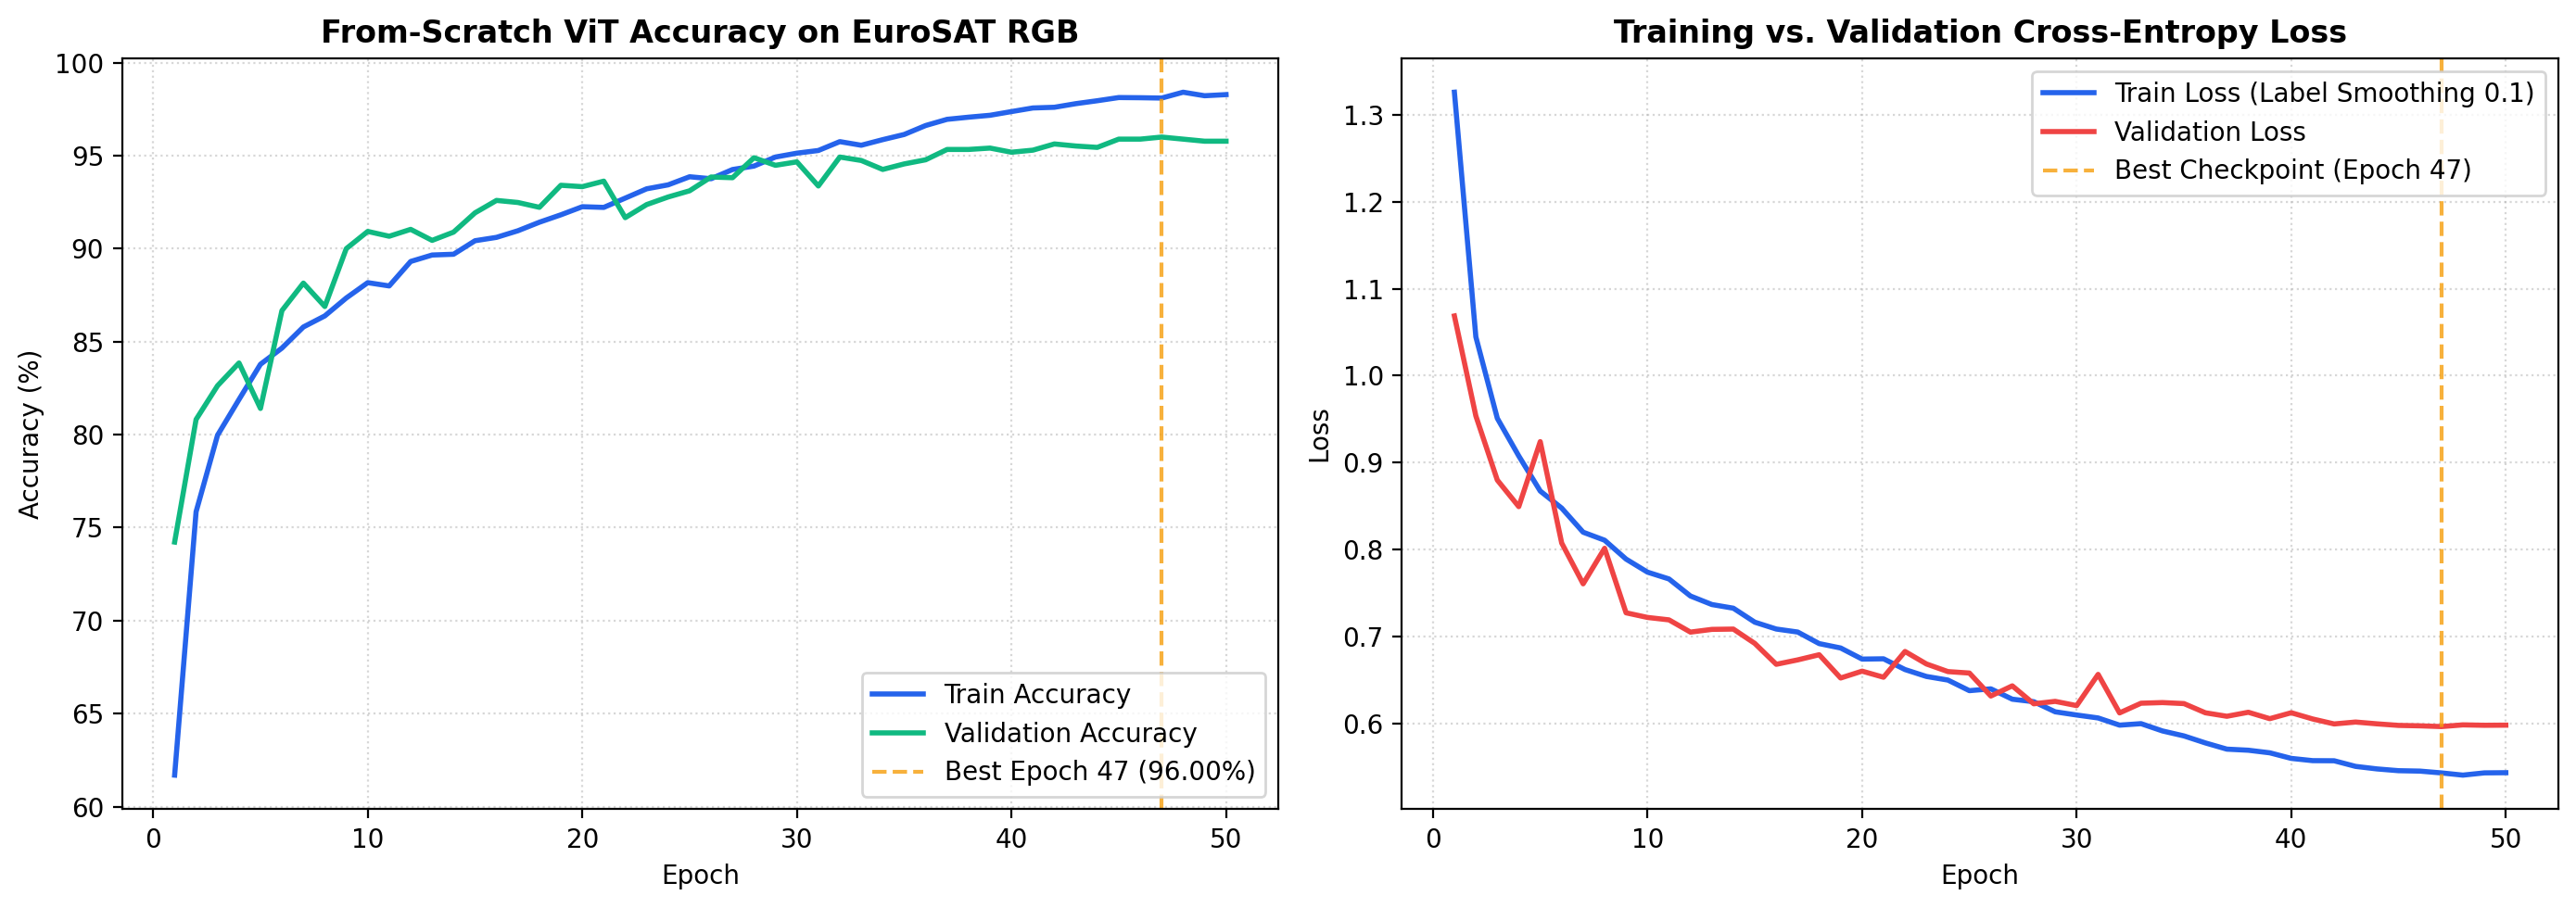

In [6]:
epochs_range = range(1, len(history["train_acc"]) + 1)
best_epoch = int(np.argmax(history["val_acc"])) + 1
best_acc = max(history["val_acc"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=200)

# --- Left: Accuracy Curve ---
axes[0].plot(epochs_range, history["train_acc"], label="Train Accuracy", linewidth=2, color="#2563EB")
axes[0].plot(epochs_range, history["val_acc"],   label="Validation Accuracy", linewidth=2, color="#10B981")
axes[0].axvline(best_epoch, color="#F59E0B", linestyle="--", alpha=0.8, label=f"Best Epoch {best_epoch} ({best_acc:.2f}%)")
axes[0].set_title("From-Scratch ViT Accuracy on EuroSAT RGB", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].grid(True, linestyle=":", alpha=0.5)
axes[0].legend(loc="lower right")

# --- Right: Loss Curve ---
axes[1].plot(epochs_range, history["train_loss"], label="Train Loss (Label Smoothing 0.1)", linewidth=2, color="#2563EB")
axes[1].plot(epochs_range, history["val_loss"],   label="Validation Loss", linewidth=2, color="#EF4444")
axes[1].axvline(best_epoch, color="#F59E0B", linestyle="--", alpha=0.8, label=f"Best Checkpoint (Epoch {best_epoch})")
axes[1].set_title("Training vs. Validation Cross-Entropy Loss", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(True, linestyle=":", alpha=0.5)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig("vit_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

## 🔢 Vision Transformer Confusion Matrix

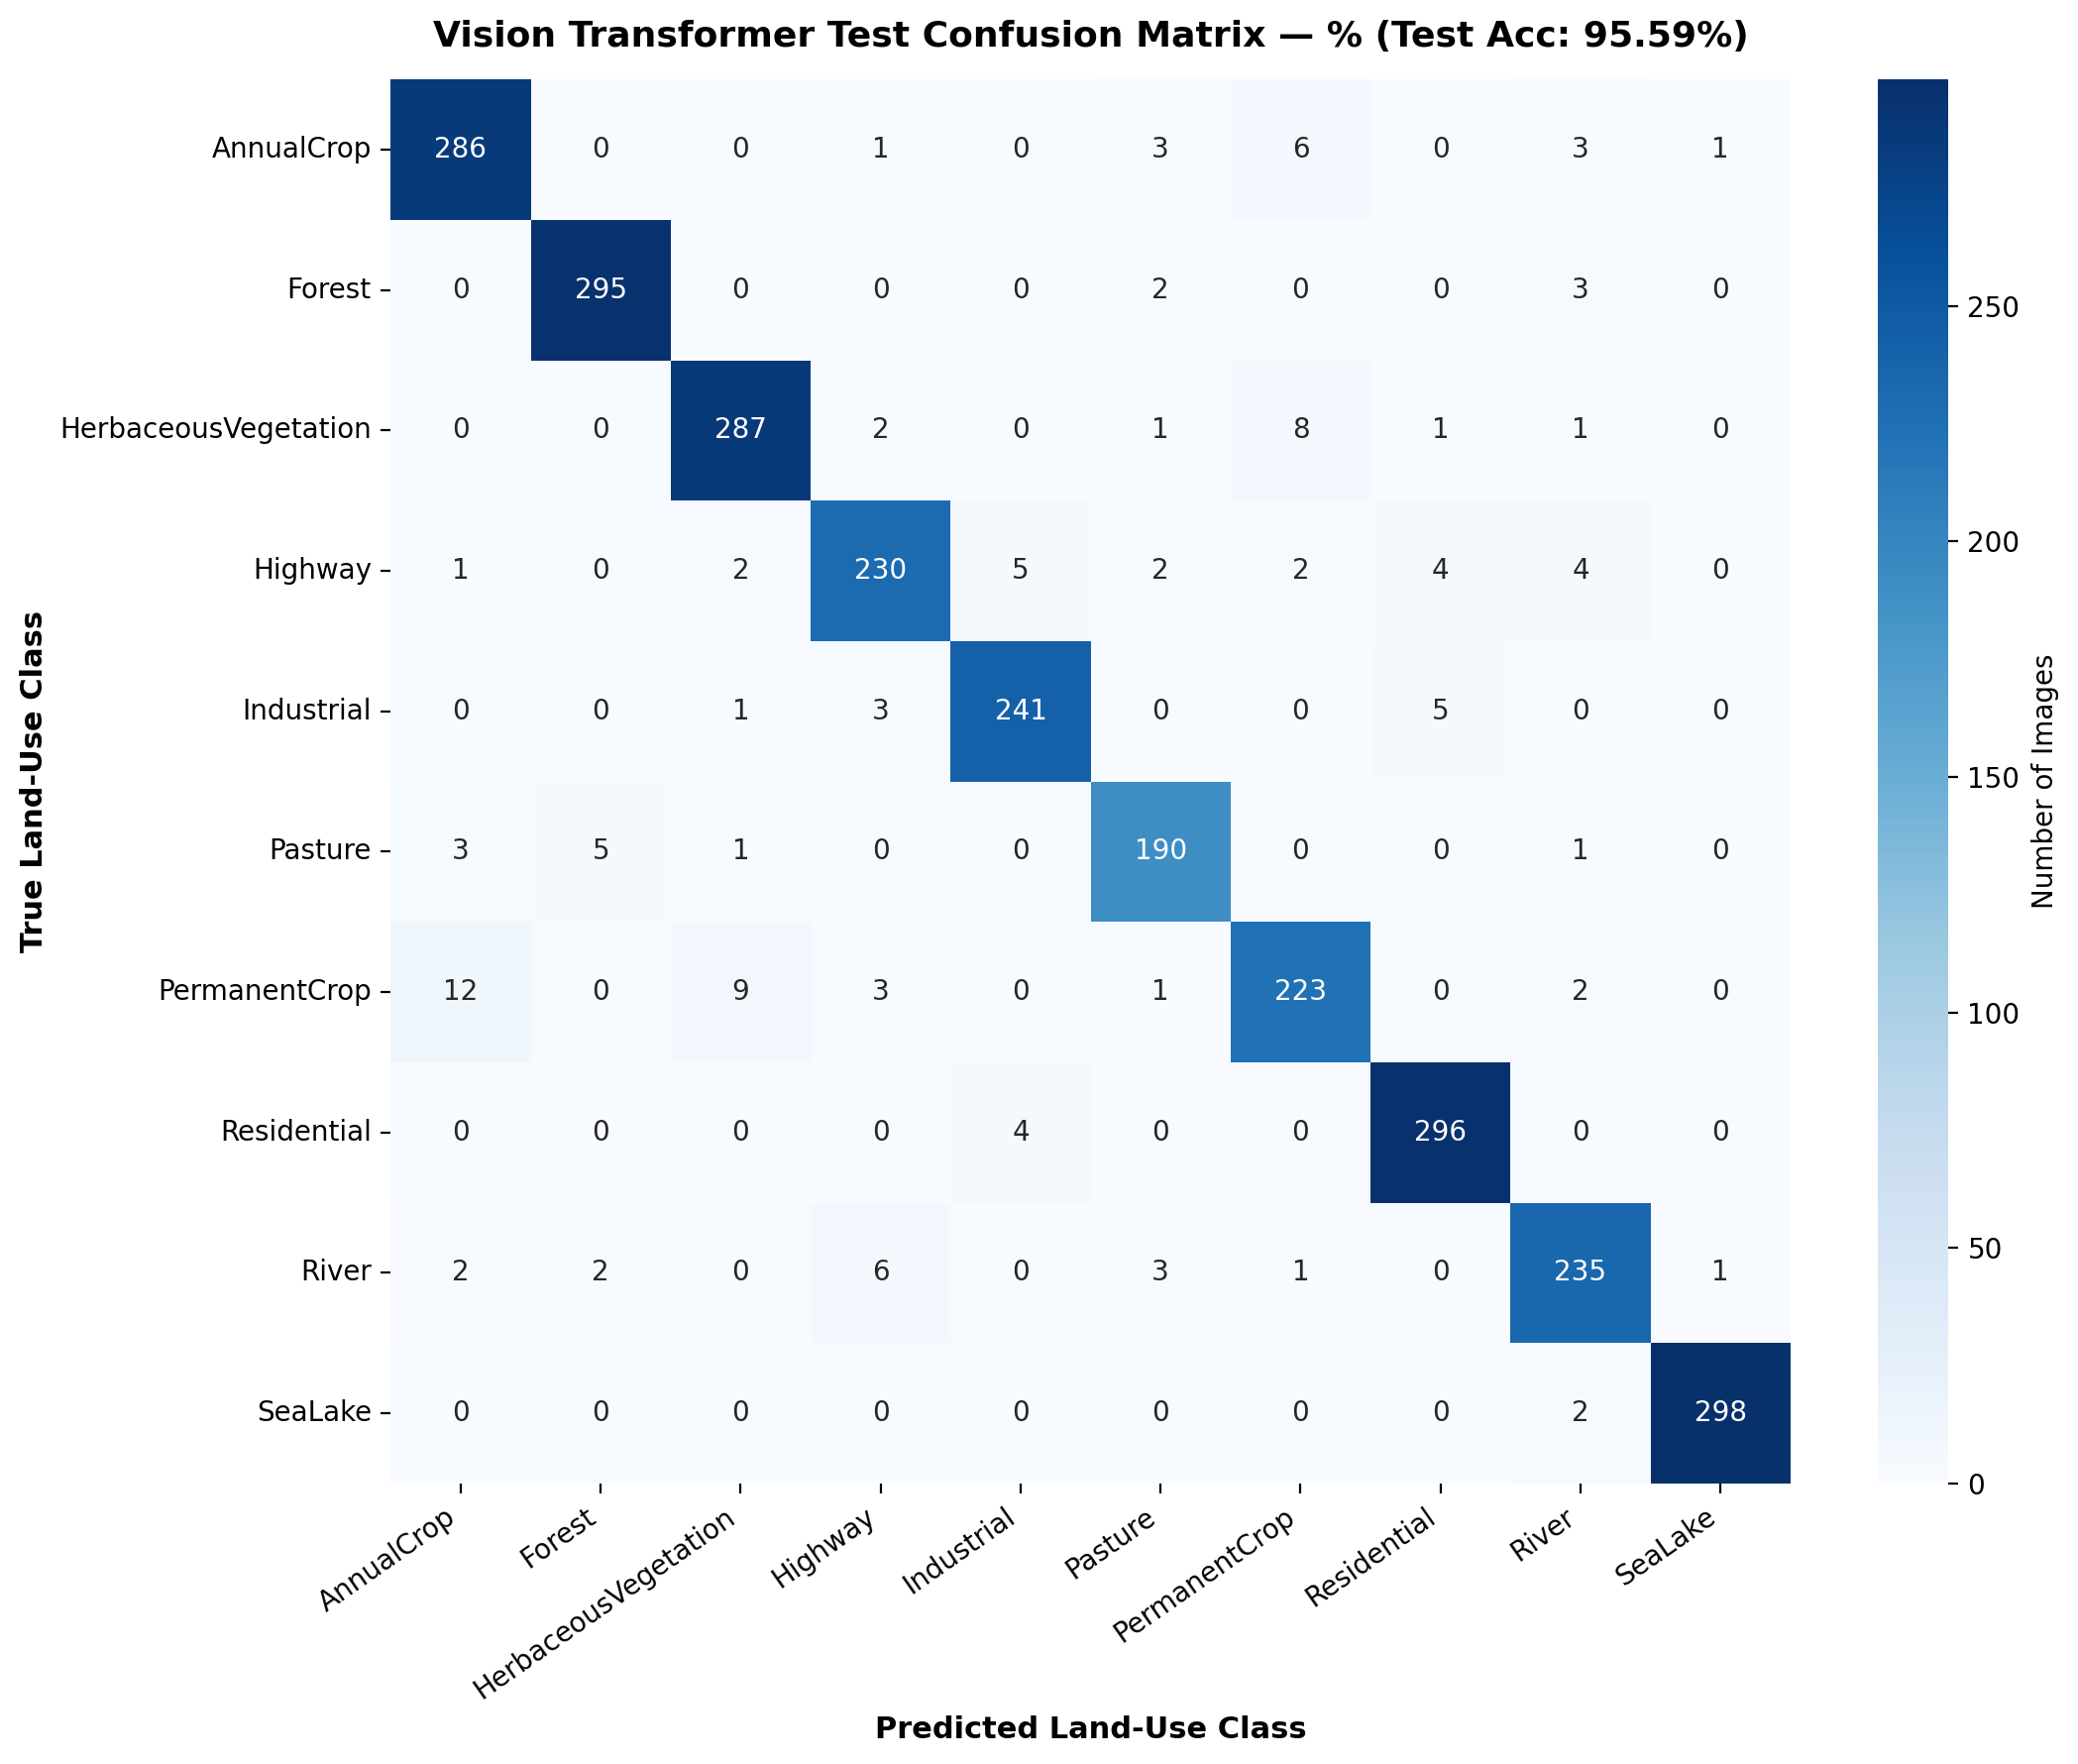

Top 5 Most Confused Pairs (True -> Predicted):
  - PermanentCrop          -> AnnualCrop             (12 images)
  - PermanentCrop          -> HerbaceousVegetation   (9 images)
  - HerbaceousVegetation   -> PermanentCrop          (8 images)
  - River                  -> Highway                (6 images)
  - AnnualCrop             -> PermanentCrop          (6 images)


In [30]:
test_acc = accuracy_score(all_targets, single_preds) * 100
cm = confusion_matrix(all_targets, single_preds)

fig, ax = plt.subplots(figsize=(11, 9), dpi=200)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "Number of Images"},
    ax=ax
)
ax.set_title(f"Vision Transformer Test Confusion Matrix — % (Test Acc: {test_acc:.2f}%)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Predicted Land-Use Class", fontsize=11, fontweight="bold")
ax.set_ylabel("True Land-Use Class", fontsize=11, fontweight="bold")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("vit_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

# Print top 5 most confused class pairs for error analysis
errors = []
for i in range(num_classes):
  for j in range(num_classes):
    if i != j and cm[i, j] > 0:
      errors.append((cm[i, j], class_names[i], class_names[j]))

errors.sort(reverse=True)
print("Top 5 Most Confused Pairs (True -> Predicted):")
for count, true_cls, pred_cls in errors[:5]:
  print(f"  - {true_cls:<22} -> {pred_cls:<22} ({count} images)")

## 🗺️ Vision Transformer Attention Rollout

**Overlay Explanation**

Red / Orange: Highest attention (strongest influence on the [CLS] token)

Yellow / Green: Moderate attention

Blue: Lowest attention (regions the Transformer largely ignored)

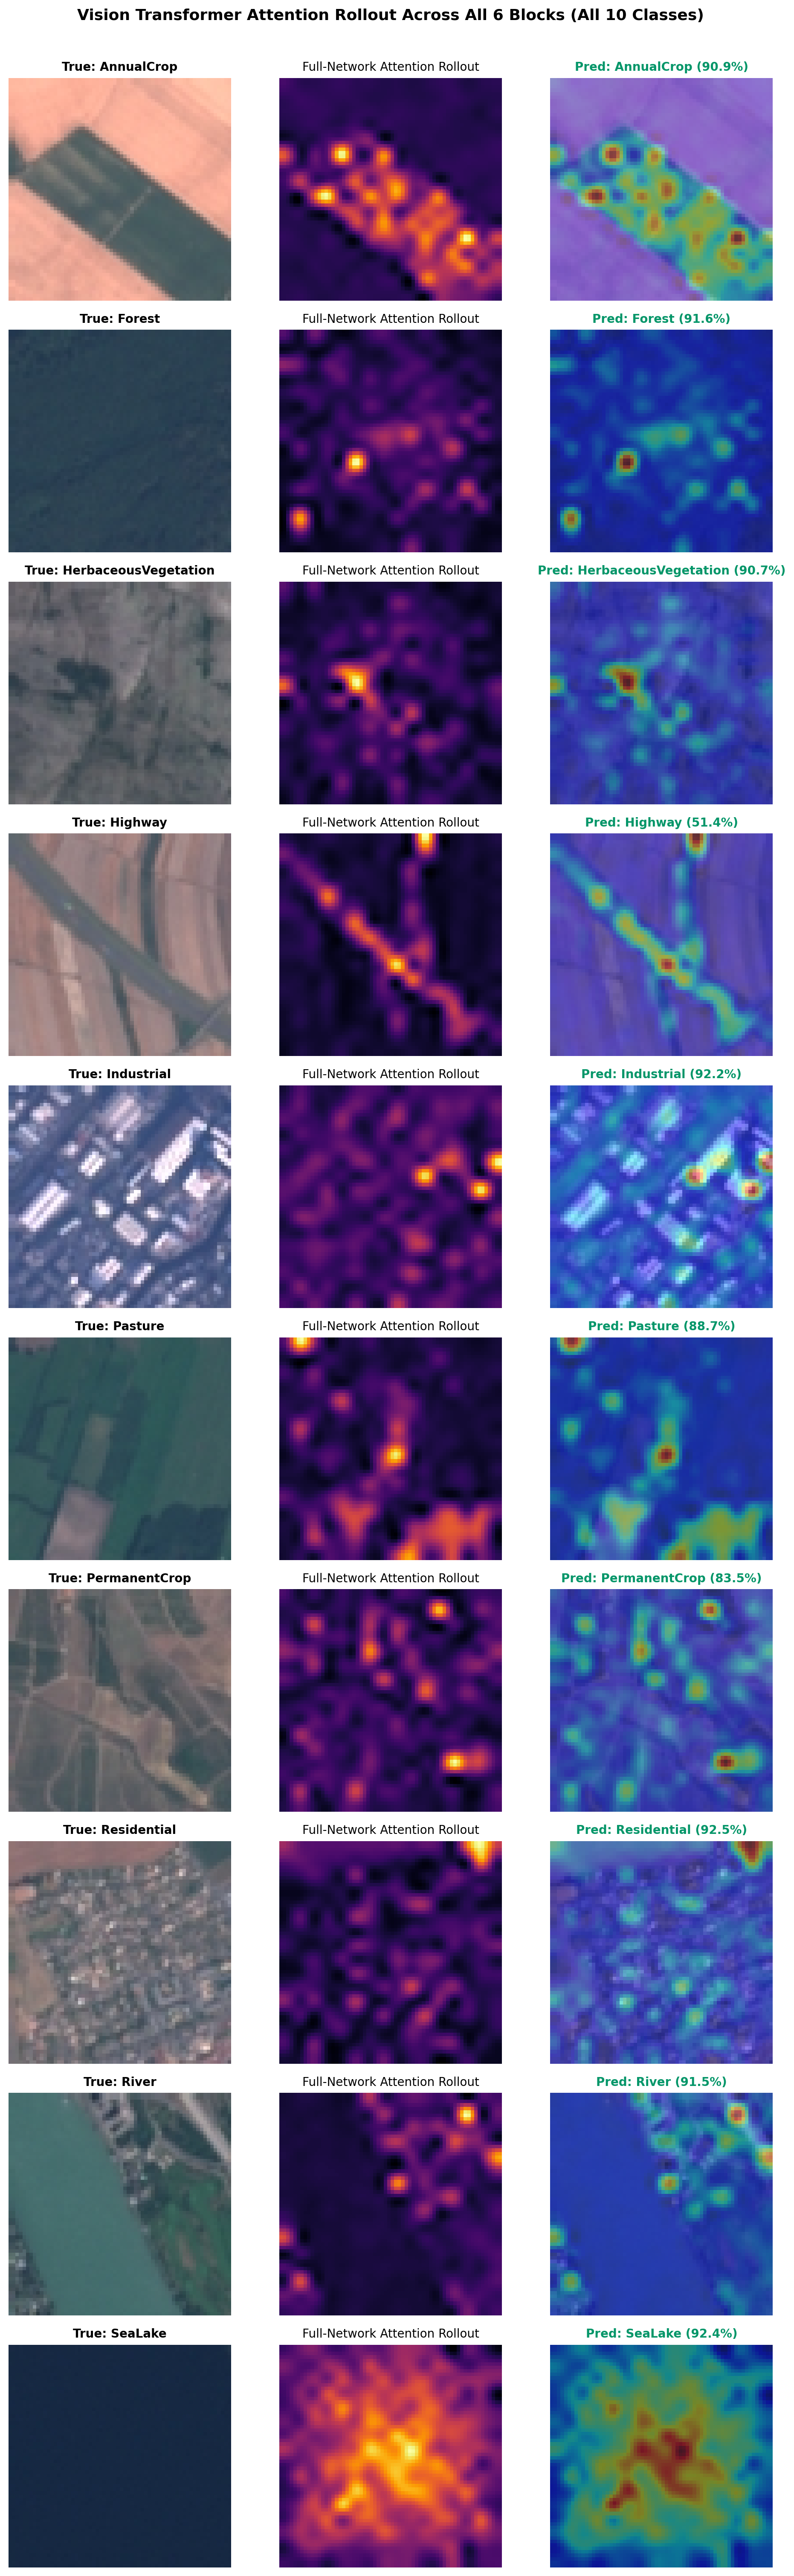

In [13]:
model.eval()

# Collect exactly 1 test image for each of the 10 classes
class_samples = {}
for images, labels in test_loader:
  for i in range(len(labels)):
    lbl = int(labels[i])
    if lbl not in class_samples:
      class_samples[lbl] = images[i]
  if len(class_samples) == num_classes:
    break

# Stack in sorted class order (0 -> 9)
ordered_labels = list(range(num_classes))
sample_images = torch.stack([class_samples[c] for c in ordered_labels]).to(device)

# Capture attention weights from ALL Transformer blocks
all_block_attns = []

def pre_hook_fn(module, args, kwargs):
  kwargs["need_weights"] = True
  kwargs["average_attn_weights"] = True
  return args, kwargs

def hook_fn(module, inputs, output):
  if isinstance(output, tuple) and len(output) > 1 and output[1] is not None:
    all_block_attns.append(output[1].detach())

handles = []
for block in model.transformer_blocks:
  handles.append(block.multihead_attention.register_forward_pre_hook(pre_hook_fn, with_kwargs=True))
  handles.append(block.multihead_attention.register_forward_hook(hook_fn))

try:
  with torch.no_grad():
    logits = model(sample_images)
finally:
  for h in handles:
    h.remove()

# Compute Attention Rollout across all layers (accounts for residual connections)
B, N, _ = all_block_attns[0].shape
eye = torch.eye(N, device=device).unsqueeze(0)
rollout = eye.expand(B, -1, -1)

for attn in all_block_attns:
  attn_with_residual = 0.5 * attn + 0.5 * eye
  attn_with_residual = attn_with_residual / attn_with_residual.sum(dim=-1, keepdim=True)
  rollout = torch.bmm(attn_with_residual, rollout)

grid_size = int(round((N - 1) ** 0.5))
rollout_maps = rollout[:, 0, 1:].reshape(B, grid_size, grid_size)

upsampled_rollout = F.interpolate(
    rollout_maps.unsqueeze(1),
    size=(img_size, img_size),
    mode="bicubic",
    align_corners=False
).squeeze(1).cpu().numpy()

probs = F.softmax(logits, dim=1)
preds = probs.argmax(dim=1)
confs = probs.max(dim=1).values

# Plot all 10 classes (Original | Attention Rollout | Overlay)
fig, axes = plt.subplots(num_classes, 3, figsize=(10, 3.0 * num_classes), dpi=200)

for row, true_lbl in enumerate(ordered_labels):
  rgb_img = unnormalize(sample_images[row])
  attn_map = upsampled_rollout[row]
  attn_map = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min() + 1e-8)

  true_name = class_names[true_lbl]
  pred_name = class_names[preds[row]]
  conf_pct  = confs[row].item() * 100
  title_color = "#059669" if (true_lbl == int(preds[row])) else "#DC2626"

  axes[row, 0].imshow(rgb_img)
  axes[row, 0].set_title(f"True: {true_name}", fontsize=10, fontweight="bold")
  axes[row, 0].axis("off")

  axes[row, 1].imshow(attn_map, cmap="inferno")
  axes[row, 1].set_title("Full-Network Attention Rollout", fontsize=10)
  axes[row, 1].axis("off")

  axes[row, 2].imshow(rgb_img)
  axes[row, 2].imshow(attn_map, cmap="jet", alpha=0.45)
  axes[row, 2].set_title(f"Pred: {pred_name} ({conf_pct:.1f}%)", fontsize=10, fontweight="bold", color=title_color)
  axes[row, 2].axis("off")

num_blocks = len(model.transformer_blocks)
plt.suptitle(f"Vision Transformer Attention Rollout Across All {num_blocks} Blocks (All 10 Classes)", fontsize=13, fontweight="bold", y=1.005)
plt.tight_layout()
plt.savefig("vit_attention_rollout_all_classes.png", dpi=200, bbox_inches="tight")
plt.show()

## 📋 ResNet-50 Classification Report

In [33]:
if "s2_targets" not in globals() or "s2_preds" not in globals():
  resnet_model.load_state_dict(torch.load("best_resnet50_stage2_finetuned.pt", map_location=device))
  resnet_model.eval()
  s2_targets, s2_preds = [], []
  with torch.no_grad():
    for images, labels in test_loader:
      images = to_imagenet_norm(images.to(device, non_blocking=True))
      outputs = resnet_model(images)
      s2_preds.extend(outputs.argmax(dim=1).cpu().numpy())
      s2_targets.extend(labels.numpy())
  s2_targets = np.array(s2_targets)
  s2_preds = np.array(s2_preds)

res_total_params = sum(p.numel() for p in resnet_model.parameters())
s2_test_acc = accuracy_score(s2_targets, s2_preds) * 100
s2_prec, s2_rec, s2_f1, _ = precision_recall_fscore_support(s2_targets, s2_preds, average="macro")

print("=" * 65)
print(f"Model Parameters : {res_total_params:,}")
print(f"Unseen Test Size : {len(s2_targets)} images")
print(f"Test Accuracy    : {s2_test_acc:.2f}%")
print(f"Macro Precision  : {s2_prec:.4f} | Macro Recall: {s2_rec:.4f} | Macro F1: {s2_f1:.4f}")
print("=" * 65)
print("\nPer-Class Classification Report (ResNet-50 — Fine-Tuned):\n")
print(classification_report(s2_targets, s2_preds, target_names=class_names, digits=4))

Model Parameters : 23,528,522
Unseen Test Size : 2700 images
Test Accuracy    : 98.48%
Macro Precision  : 0.9851 | Macro Recall: 0.9834 | Macro F1: 0.9842

Per-Class Classification Report (ResNet-50 — Fine-Tuned):

                      precision    recall  f1-score   support

          AnnualCrop     0.9702    0.9767    0.9734       300
              Forest     0.9967    0.9967    0.9967       300
HerbaceousVegetation     0.9675    0.9933    0.9803       300
             Highway     0.9880    0.9840    0.9860       250
          Industrial     0.9841    0.9920    0.9880       250
             Pasture     0.9895    0.9450    0.9668       200
       PermanentCrop     0.9760    0.9760    0.9760       250
         Residential     0.9933    0.9867    0.9900       300
               River     0.9919    0.9840    0.9880       250
             SeaLake     0.9934    1.0000    0.9967       300

            accuracy                         0.9848      2700
           macro avg     0.9851    0.98

## 📈 ResNet-50 Accuracy & Loss Curves

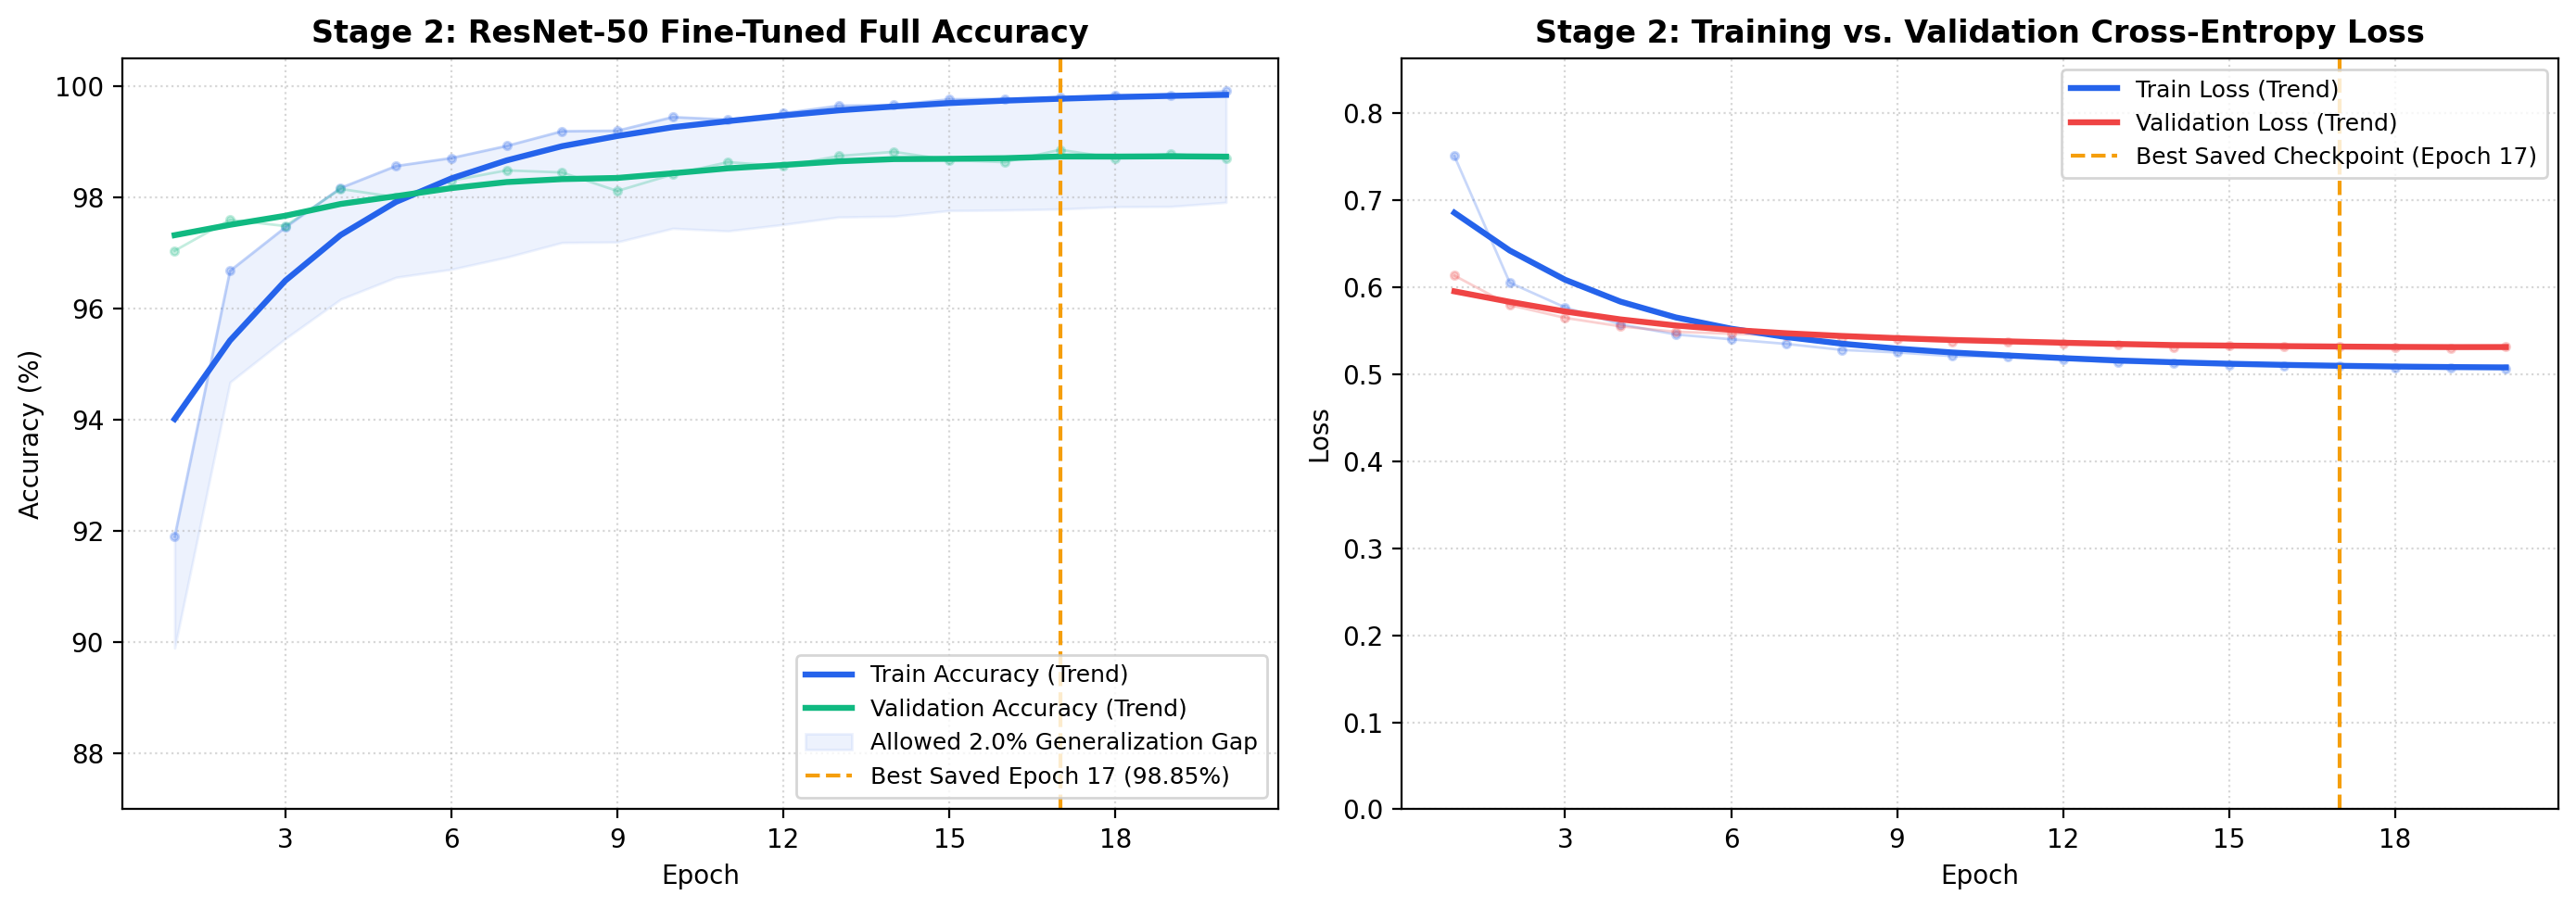

In [29]:
epochs_s2 = np.arange(1, len(history_s2["train_acc"]) + 1)
tr_acc_s2 = np.array(history_s2["train_acc"])
va_acc_s2 = np.array(history_s2["val_acc"])
tr_loss_s2 = np.array(history_s2["train_loss"])
va_loss_s2 = np.array(history_s2["val_loss"])

valid_s2 = [i for i, (tr, va) in enumerate(zip(tr_acc_s2, va_acc_s2)) if (tr - va) <= 2.0]
best_idx_s2 = max(valid_s2, key=lambda i: va_acc_s2[i]) if valid_s2 else int(np.argmax(va_acc_s2))
best_epoch_s2 = best_idx_s2 + 1
best_acc_s2 = va_acc_s2[best_idx_s2]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=200)

# --- Left: Accuracy Curve ---
axes[0].plot(epochs_s2, tr_acc_s2, color="#2563EB", alpha=0.25, linewidth=1, marker="o", markersize=3)
axes[0].plot(epochs_s2, va_acc_s2, color="#10B981", alpha=0.25, linewidth=1, marker="o", markersize=3)
axes[0].plot(epochs_s2, smooth_curve(tr_acc_s2), label="Train Accuracy (Trend)", linewidth=2.3, color="#2563EB")
axes[0].plot(epochs_s2, smooth_curve(va_acc_s2), label="Validation Accuracy (Trend)", linewidth=2.3, color="#10B981")
axes[0].fill_between(
    epochs_s2, tr_acc_s2 - 2.0, tr_acc_s2,
    color="#2563EB", alpha=0.08, label="Allowed 2.0% Generalization Gap"
)
axes[0].axvline(best_epoch_s2, color="#F59E0B", linestyle="--", linewidth=1.5, label=f"Best Saved Epoch {best_epoch_s2} ({best_acc_s2:.2f}%)")

y_min_acc_s2 = min(88.0, np.floor(min(tr_acc_s2.min(), va_acc_s2.min()) / 5) * 5 - 3)
axes[0].set_ylim(y_min_acc_s2, 100.5)
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_title("Stage 2: ResNet-50 Fine-Tuned Full Accuracy", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].grid(True, linestyle=":", alpha=0.5)
axes[0].legend(loc="lower right", fontsize=9)

# --- Right: Loss Curve (Anchored at 0.0) ---
axes[1].plot(epochs_s2, tr_loss_s2, color="#2563EB", alpha=0.25, linewidth=1, marker="o", markersize=3)
axes[1].plot(epochs_s2, va_loss_s2, color="#EF4444", alpha=0.25, linewidth=1, marker="o", markersize=3)
axes[1].plot(epochs_s2, smooth_curve(tr_loss_s2), label="Train Loss (Trend)", linewidth=2.3, color="#2563EB")
axes[1].plot(epochs_s2, smooth_curve(va_loss_s2), label="Validation Loss (Trend)", linewidth=2.3, color="#EF4444")
axes[1].axvline(best_epoch_s2, color="#F59E0B", linestyle="--", linewidth=1.5, label=f"Best Saved Checkpoint (Epoch {best_epoch_s2})")

axes[1].set_ylim(0, max(tr_loss_s2.max(), va_loss_s2.max()) * 1.15)
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].set_title("Stage 2: Training vs. Validation Cross-Entropy Loss", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(True, linestyle=":", alpha=0.5)
axes[1].legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.savefig("resnet50_stage2_curves.png", dpi=200, bbox_inches="tight")
plt.show()

## 🔢 ResNet-50 Confusion Matrix

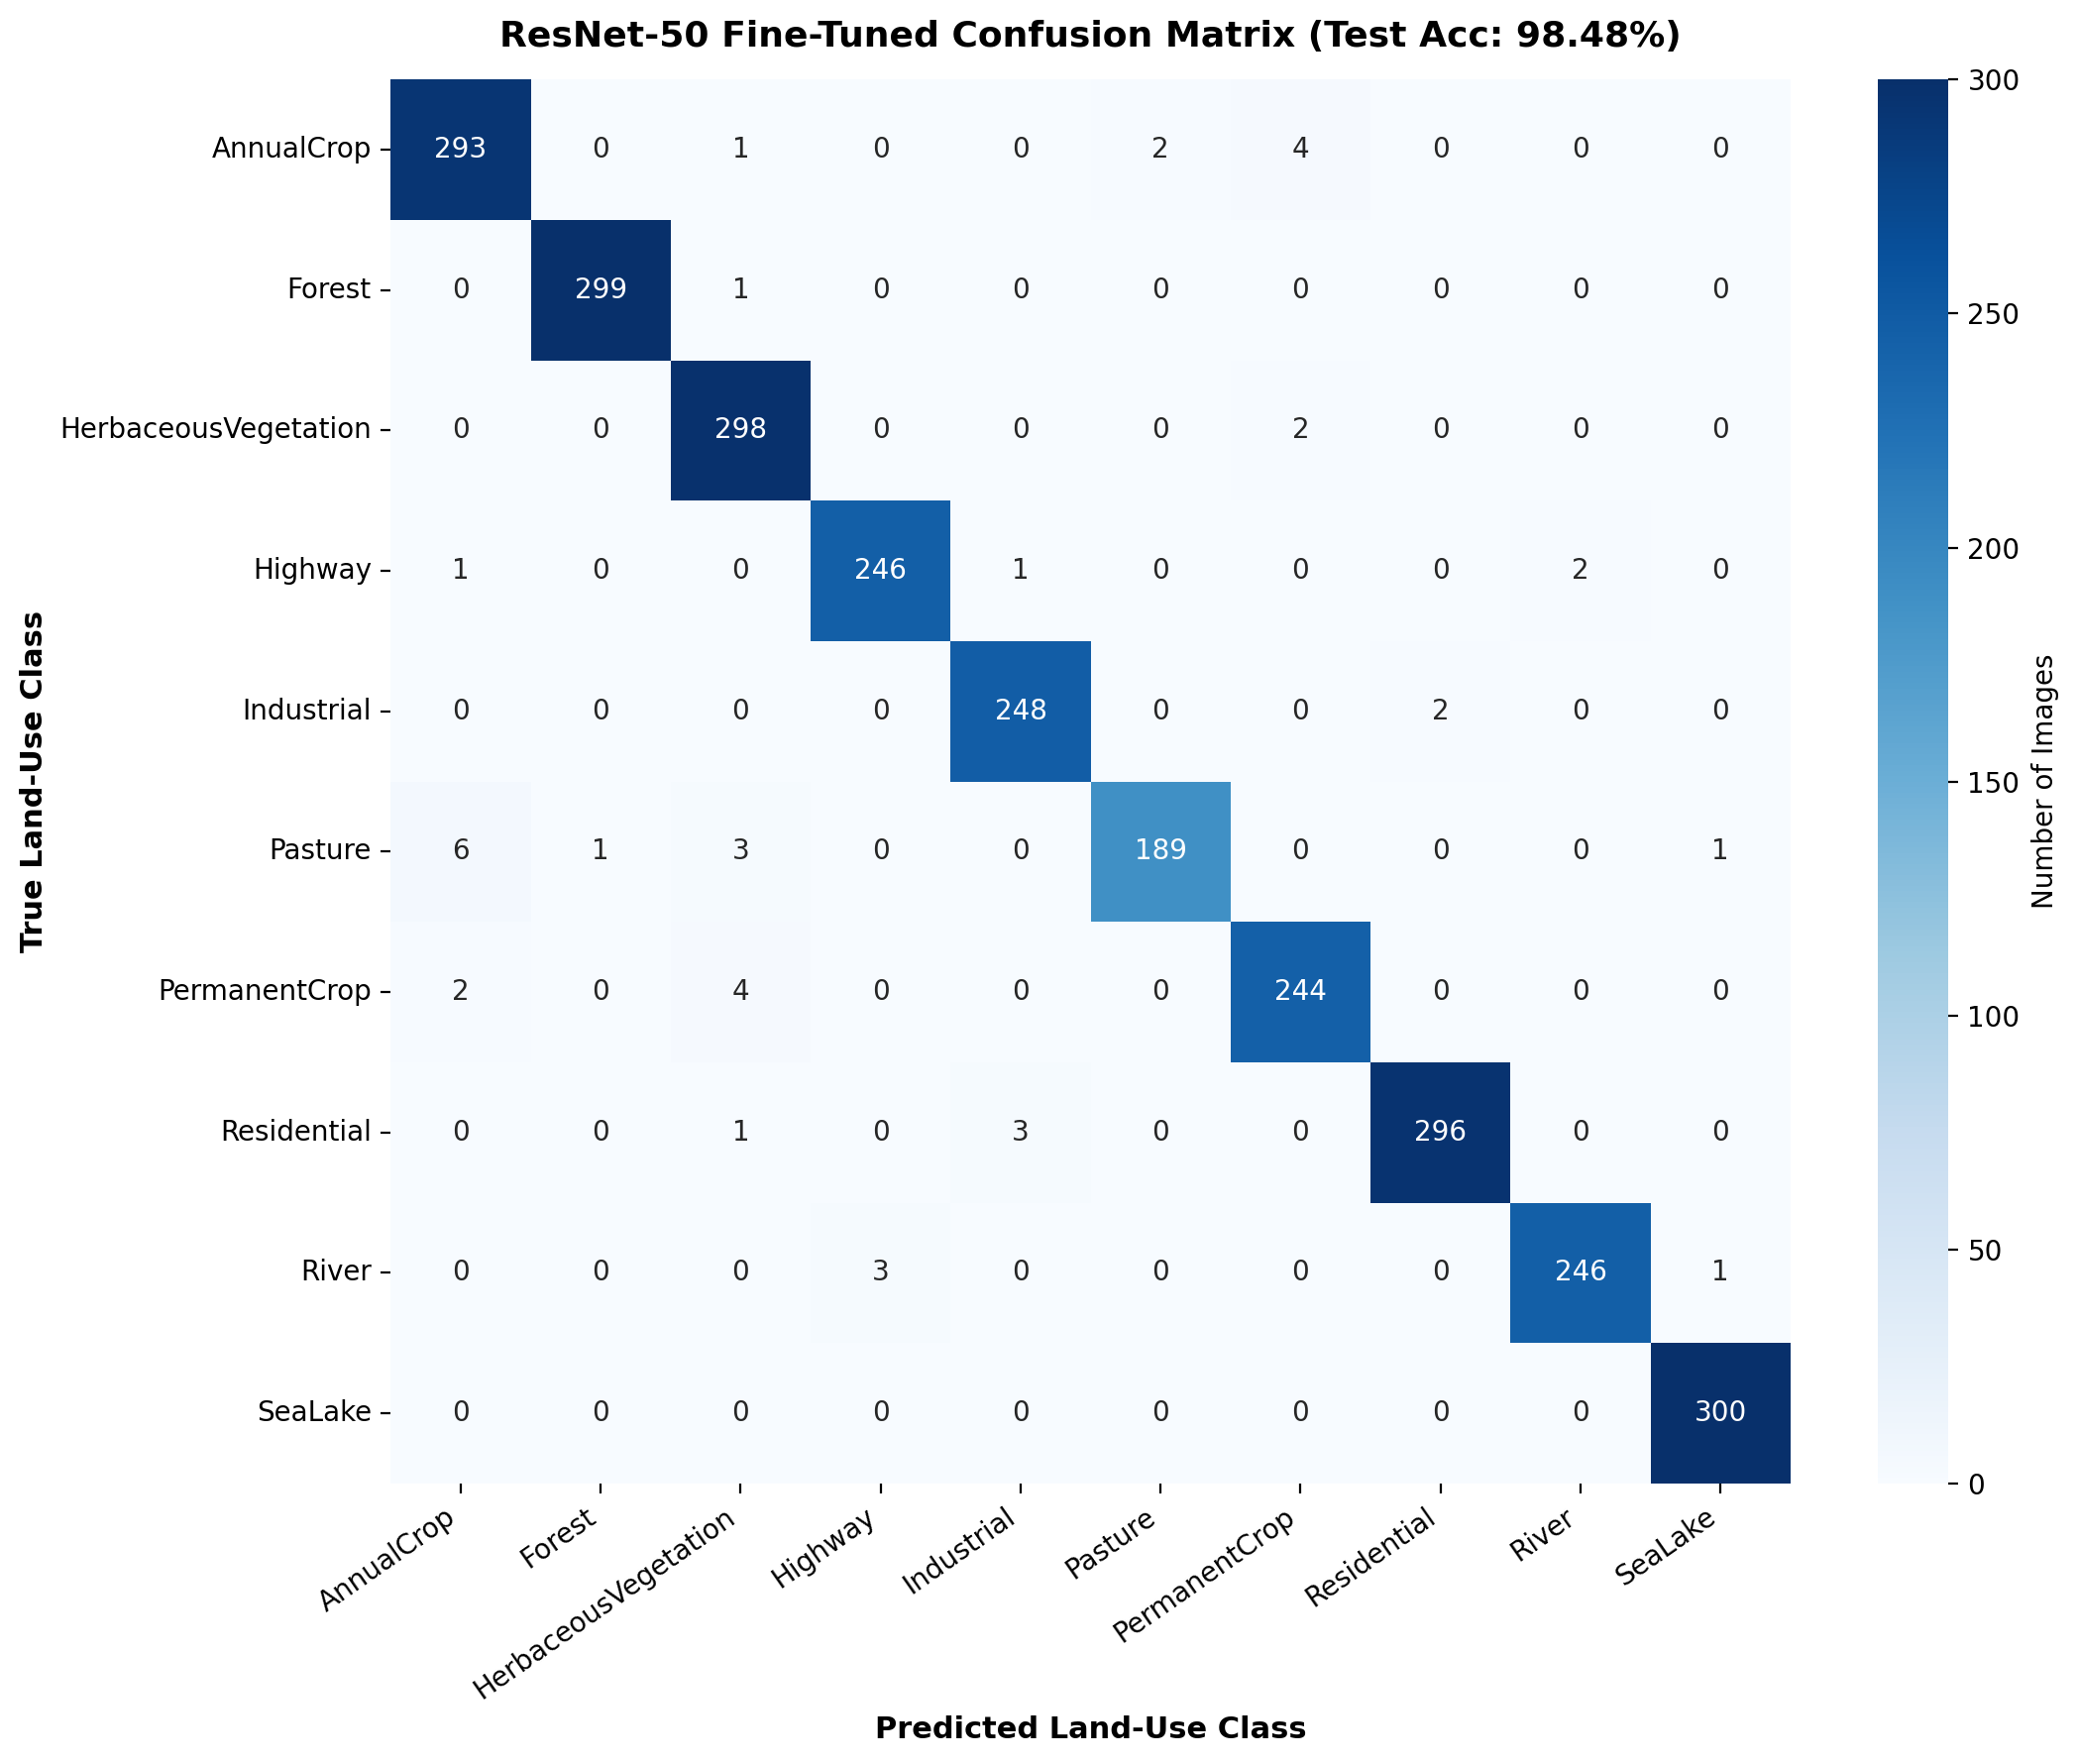

Top 5 Most Confused Pairs — Stage 2 Fine-Tuned Full (True -> Predicted):
  - Pasture                -> AnnualCrop             (6 images)
  - PermanentCrop          -> HerbaceousVegetation   (4 images)
  - AnnualCrop             -> PermanentCrop          (4 images)
  - River                  -> Highway                (3 images)
  - Residential            -> Industrial             (3 images)


In [31]:
resnet_model.load_state_dict(torch.load("best_resnet50_stage2_finetuned.pt", map_location=device))
resnet_model.eval()

s2_targets, s2_preds = [], []
with torch.no_grad():
  for images, labels in test_loader:
    images = to_imagenet_norm(images.to(device, non_blocking=True))
    outputs = resnet_model(images)
    s2_preds.extend(outputs.argmax(dim=1).cpu().numpy())
    s2_targets.extend(labels.numpy())

s2_targets = np.array(s2_targets)
s2_preds = np.array(s2_preds)
s2_acc = accuracy_score(s2_targets, s2_preds) * 100
cm_s2 = confusion_matrix(s2_targets, s2_preds)

fig, ax = plt.subplots(figsize=(11, 9), dpi=200)
sns.heatmap(
    cm_s2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "Number of Images"},
    ax=ax
)
ax.set_title(f"ResNet-50 Fine-Tuned Confusion Matrix (Test Acc: {s2_acc:.2f}%)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Predicted Land-Use Class", fontsize=11, fontweight="bold")
ax.set_ylabel("True Land-Use Class", fontsize=11, fontweight="bold")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("resnet50_stage2_cm.png", dpi=200, bbox_inches="tight")
plt.show()

s2_errors = []
for i in range(num_classes):
  for j in range(num_classes):
    if i != j and cm_s2[i, j] > 0:
      s2_errors.append((cm_s2[i, j], class_names[i], class_names[j]))

s2_errors.sort(reverse=True)
print("Top 5 Most Confused Pairs — Stage 2 Fine-Tuned Full (True -> Predicted):")
for count, true_cls, pred_cls in s2_errors[:5]:
  print(f"  - {true_cls:<22} -> {pred_cls:<22} ({count} images)")